# RNN for Time Series Forecasting: Melbourne Daily Minimum Temperatures
Simple PyTorch implementation. Given the last 30 days, the model predicts tomorrow's minimum temperature.

Structure adapted from J. Canary, *Recurrent Neural Networks (RNNs) and LSTMs*, Medium, with the synthetic data replaced by a real dataset.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

## 2. Load the data
- Values like `?0.2` lost their minus sign in the original file, so `?` is replaced with `-`.
- Two missing days are filled by interpolation, so each RNN step is exactly one day.
- **Chronological split:** 1981–1989 for training, 1990 for testing.
- **Min-max scaling** to [0, 1], fitted on the training data only.
- **Sliding windows:** 30 days in → the next day out.

Train: torch.Size([3257, 30, 1]) | Test: torch.Size([365, 30, 1])


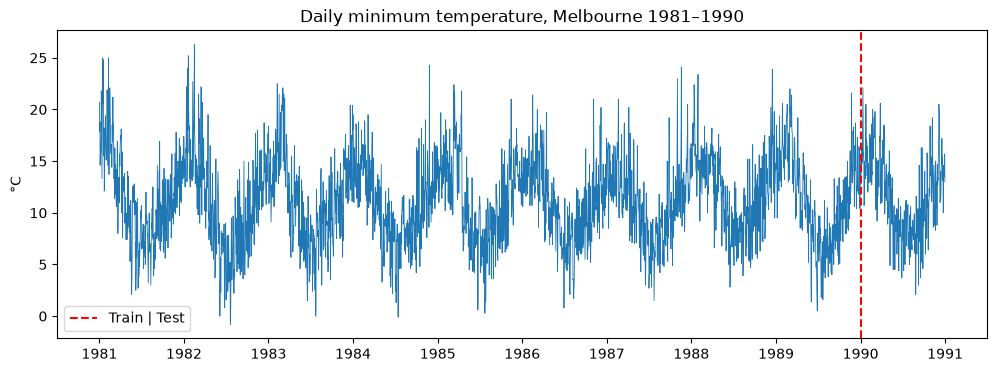

In [2]:
df = pd.read_csv("daily-minimum-temperatures-in-me.csv", skipfooter=2, engine="python")
df.columns = ["Date", "Temp"]
df["Temp"] = df["Temp"].astype(str).str.replace("?", "-").astype(float)
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").asfreq("D").interpolate()

train = df.loc[:"1989", "Temp"].values
test  = df.loc["1990", "Temp"].values

t_min, t_max = train.min(), train.max()
scale   = lambda x: (x - t_min) / (t_max - t_min)
unscale = lambda x: x * (t_max - t_min) + t_min

WINDOW = 30

def make_windows(series, window):
    X, y = [], []
    for i in range(len(series) - window):
        X.append(series[i:i + window])
        y.append(series[i + window])
    return np.array(X), np.array(y)

train_s = scale(train)
test_s  = scale(np.concatenate([train[-WINDOW:], test]))   # last 30 days of 1989 feed the first 1990 forecast

X_train, y_train = make_windows(train_s, WINDOW)
X_test,  y_test  = make_windows(test_s, WINDOW)

# PyTorch RNN input shape: (samples, timesteps, features)
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1)
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)
X_test  = torch.tensor(X_test,  dtype=torch.float32).unsqueeze(-1)
y_test  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(-1)

print("Train:", X_train.shape, "| Test:", X_test.shape)

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Temp"], lw=0.6)
plt.axvline(pd.Timestamp("1990-01-01"), color="red", ls="--", label="Train | Test")
plt.title("Daily minimum temperature, Melbourne 1981–1990"); plt.ylabel("°C"); plt.legend()
plt.show()

## 3. Define the RNN model
$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h) \qquad \hat{y} = W_{hy}h_{30} + b_y$$
One recurrent layer with 16 hidden units. Only the **last hidden state** goes to the linear output layer (many-to-one).

In [3]:
class RNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)   # tanh by default
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, h_n = self.rnn(x)        # out: hidden state at every step
        return self.fc(out[:, -1, :]) # keep only the last one

model = RNNModel()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

RNNModel(
  (rnn): RNN(1, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 321


## 4. Train the RNN
Full-batch training with Backpropagation Through Time (PyTorch computes it with `loss.backward()`).

Epoch 50/300, Loss: 0.01345
Epoch 100/300, Loss: 0.00852
Epoch 150/300, Loss: 0.00812
Epoch 200/300, Loss: 0.00796
Epoch 250/300, Loss: 0.00805
Epoch 300/300, Loss: 0.00794


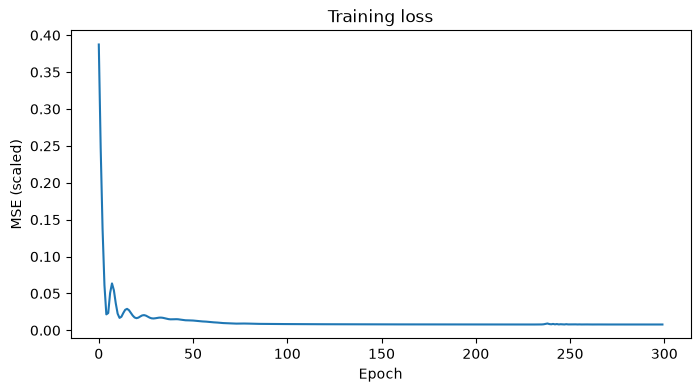

In [4]:
EPOCHS = 300
losses = []

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()          # BPTT
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS}, Loss: {loss.item():.5f}")

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.title("Training loss"); plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)")
plt.show()

## 5. Evaluate the RNN
Predictions are converted back to °C. As a reference we compare with the **naïve forecast** (tomorrow = today).

                  SSE    MSE   RMSE    MAE     R²
Model                                            
RNN          1864.544  5.108  2.260  1.739  0.656
Naïve (t-1)  2434.110  6.669  2.582  2.025  0.552


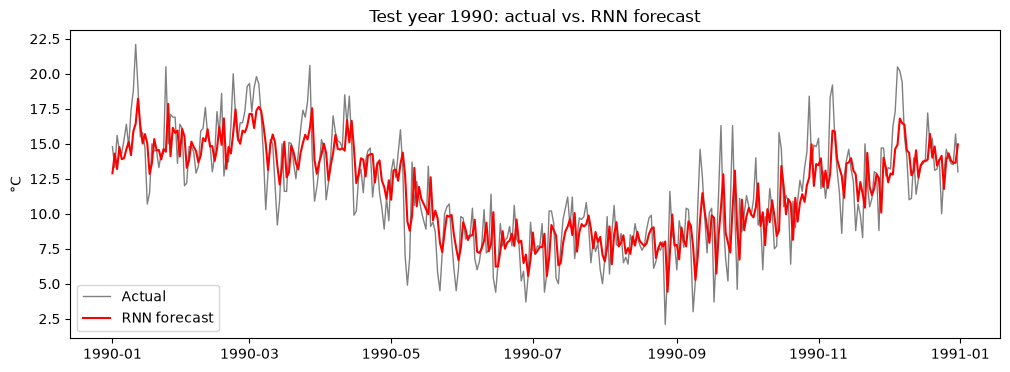

In [5]:
model.eval()
with torch.no_grad():
    pred = unscale(model(X_test).numpy().ravel())

actual = test
naive  = np.concatenate([[train[-1]], test[:-1]])

def report(name, y, p):
    e = y - p
    sse  = np.sum(e ** 2)
    mse  = np.mean(e ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(e))
    r2   = 1 - sse / np.sum((y - y.mean()) ** 2)
    return {"Model": name, "SSE": sse, "MSE": mse, "RMSE": rmse, "MAE": mae, "R²": r2}

results = pd.DataFrame([report("RNN", actual, pred),
                        report("Naïve (t-1)", actual, naive)]).set_index("Model")
print(results.round(3))

dates = df.loc["1990"].index
plt.figure(figsize=(12, 4))
plt.plot(dates, actual, lw=1, color="gray", label="Actual")
plt.plot(dates, pred, lw=1.5, color="red", label="RNN forecast")
plt.title("Test year 1990: actual vs. RNN forecast"); plt.ylabel("°C"); plt.legend()
plt.show()

## 6. Looking inside: the vanishing gradient
How much does each of the 30 input days influence the forecast? We compute $\left|\partial \hat{y} / \partial x_t\right|$ for every time step, averaged over the test windows.
During backpropagation the gradient is multiplied by $W_{hh}$ and $\tanh'$ at every step back in time, so **older days receive much smaller gradients**.

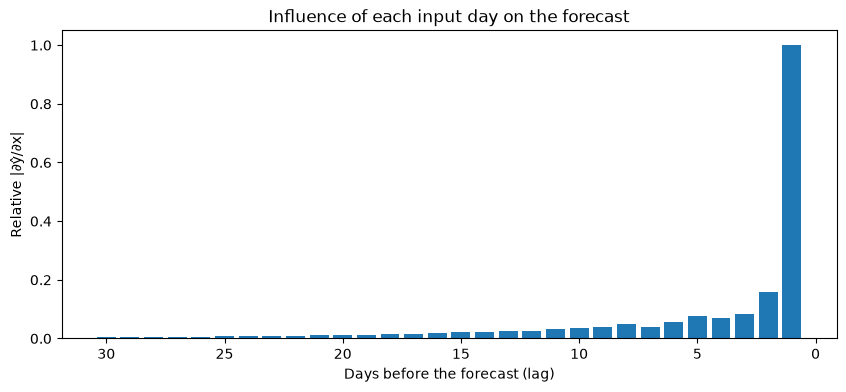

lag  1: relative influence = 1.000
lag  2: relative influence = 0.157
lag  5: relative influence = 0.075
lag 10: relative influence = 0.035
lag 20: relative influence = 0.012
lag 30: relative influence = 0.004


In [6]:
X_grad = X_test.clone().requires_grad_(True)
model(X_grad).sum().backward()                       # gradient of every forecast w.r.t. its inputs

influence = X_grad.grad.abs().mean(dim=0).squeeze().numpy()
influence = influence / influence.max()              # relative to the most influential day

lags = np.arange(WINDOW, 0, -1)                      # 30 = oldest day, 1 = yesterday
plt.figure(figsize=(10, 4))
plt.bar(lags, influence)
plt.gca().invert_xaxis()
plt.title("Influence of each input day on the forecast")
plt.xlabel("Days before the forecast (lag)"); plt.ylabel("Relative |∂ŷ/∂x|")
plt.show()

for lag in [1, 2, 5, 10, 20, 30]:
    print(f"lag {lag:>2}: relative influence = {influence[WINDOW - lag]:.3f}")

## 7. Animation: the sliding window in action
The 30-day input window slides across 1990, one forecast per day.
- **Top:** actual temperatures (gray) and the RNN forecast (red) being drawn day by day; the blue band is the current input window.
- **Bottom left:** the 30 values $x_1 \dots x_{30}$ that enter the RNN, and the next-day forecast $\hat{y}$ vs. the actual value.
- **Bottom right:** the influence $|\partial \hat{y}/\partial x_t|$ of each input day on *that* forecast. The bars stay concentrated on the most recent days in every window, which is the vanishing gradient from section 6 seen live.

The GIF is also saved to disk (`rnn_forecast_animation.gif`) so it can be embedded in the slides.

Saved rnn_forecast_animation.gif


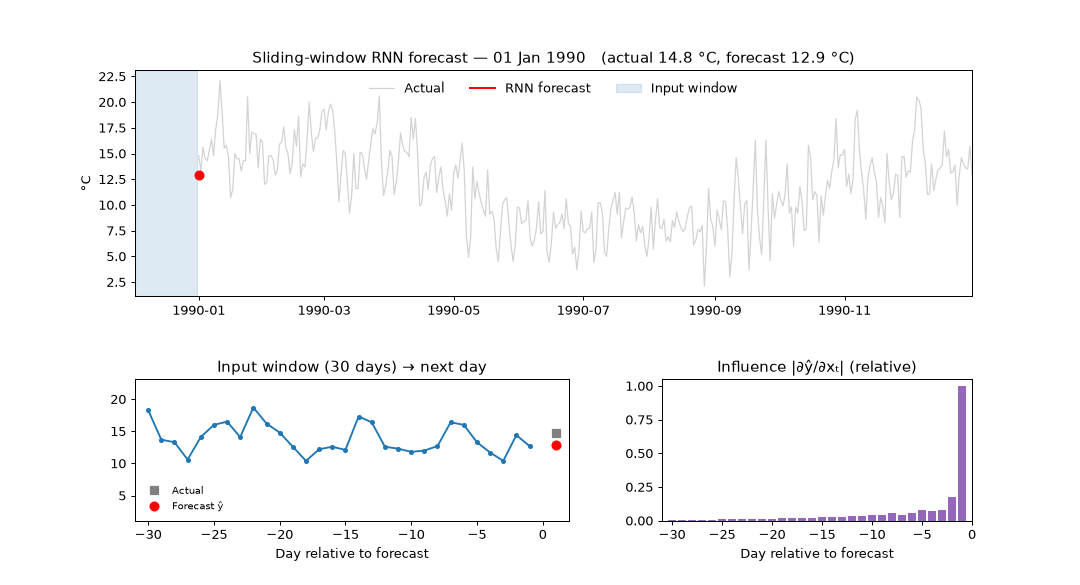

In [7]:
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.gridspec import GridSpec

# Per-window influence |dŷ/dx_t| for every test forecast (same idea as section 6, but one bar set per day)
X_grad = X_test.clone().requires_grad_(True)
model(X_grad).sum().backward()
infl_all = X_grad.grad.abs().squeeze(-1).numpy()          # (365, 30)
infl_all = infl_all / infl_all.max(axis=1, keepdims=True)  # relative to the strongest day of each window

history = np.concatenate([train[-WINDOW:], test])          # raw °C, aligned with X_test windows
hist_dates = pd.date_range(dates[0] - pd.Timedelta(days=WINDOW), periods=len(history), freq="D")

STEP = 3                                                   # draw every 3rd day → ~120 frames
frames = list(range(0, len(test), STEP)) + [len(test) - 1]

fig = plt.figure(figsize=(12, 6.5))
gs = GridSpec(2, 2, height_ratios=[1.6, 1], width_ratios=[1.4, 1], hspace=0.45, wspace=0.25)
ax_top = fig.add_subplot(gs[0, :])
ax_win = fig.add_subplot(gs[1, 0])
ax_inf = fig.add_subplot(gs[1, 1])

# Top: the whole test year, filled in as the window slides
ax_top.plot(dates, actual, color="lightgray", lw=1, label="Actual")
line_pred, = ax_top.plot([], [], color="red", lw=1.6, label="RNN forecast")
span = [ax_top.axvspan(hist_dates[0], hist_dates[WINDOW - 1], color="tab:blue", alpha=0.15, label="Input window")]
dot, = ax_top.plot([], [], "o", color="red", ms=7)
ax_top.set_xlim(hist_dates[0], dates[-1])
ax_top.set_ylim(min(actual.min(), pred.min()) - 1, max(actual.max(), pred.max()) + 1)
ax_top.set_ylabel("°C"); ax_top.legend(loc="upper center", ncol=3, frameon=False)
title = ax_top.set_title("")

# Bottom-left: the 30-day input sequence x_1 ... x_30 feeding the RNN
lags = np.arange(-WINDOW, 0)
win_line, = ax_win.plot(lags, np.zeros(WINDOW), "o-", color="tab:blue", ms=3)
pt_actual, = ax_win.plot([1], [0], "s", color="gray", ms=7, label="Actual")
pt_pred,   = ax_win.plot([1], [0], "o", color="red", ms=7, label="Forecast ŷ")
ax_win.set_xlim(-WINDOW - 1, 2); ax_win.set_ylim(ax_top.get_ylim())
ax_win.set_title("Input window (30 days) → next day"); ax_win.set_xlabel("Day relative to forecast")
ax_win.legend(loc="lower left", fontsize=8, frameon=False)

# Bottom-right: how much each input day influences this forecast (vanishing gradient)
bars = ax_inf.bar(lags, np.zeros(WINDOW), color="tab:purple")
ax_inf.set_ylim(0, 1.05); ax_inf.set_xlim(-WINDOW - 1, 0)
ax_inf.set_title("Influence |∂ŷ/∂xₜ| (relative)"); ax_inf.set_xlabel("Day relative to forecast")

def update(i):
    t_end = WINDOW + i                                       # index in `history` of the forecast day
    window = history[i:t_end]
    span[0].remove()                                         # move the shaded 30-day window
    span[0] = ax_top.axvspan(hist_dates[i], hist_dates[t_end - 1], color="tab:blue", alpha=0.15)
    line_pred.set_data(dates[:i + 1], pred[:i + 1])
    dot.set_data([dates[i]], [pred[i]])
    win_line.set_ydata(window)
    pt_actual.set_ydata([actual[i]]); pt_pred.set_ydata([pred[i]])
    for b, h in zip(bars, infl_all[i]):
        b.set_height(h)
    title.set_text(f"Sliding-window RNN forecast — {dates[i]:%d %b %Y}   "
                   f"(actual {actual[i]:.1f} °C, forecast {pred[i]:.1f} °C)")
    return line_pred, dot, win_line, pt_actual, pt_pred, *bars

anim = FuncAnimation(fig, update, frames=frames, interval=100, blit=False)
anim.save("rnn_forecast_animation.gif", writer=PillowWriter(fps=10), dpi=90)
plt.close(fig)
print("Saved rnn_forecast_animation.gif")

# Show it inside the notebook
from IPython.display import Image
Image(filename="rnn_forecast_animation.gif")


**Takeaway:** the forecast relies almost entirely on the last few days. Inputs from weeks ago barely affect it, so a plain RNN cannot exploit long-term patterns such as the yearly seasonality. This is the limitation that motivates **LSTM** and **GRU**.